### Wahrscheinlichkeit: Laplace, Pfadregeln, Vierfeldertafel, Binomialverteilung - Übungen

In diesem Notebook berechnest du **Wahrscheinlichkeiten** mit sympy: Ereignisse als Mengen, Laplace-Experimente, Kombinatorik,
Baumdiagramme und Pfadregeln, Vierfeldertafeln und bedingte Wahrscheinlichkeiten, Zufallsgrößen mit Erwartungswert und die
**Binomialverteilung**. sympy rechnet dabei mit **exakten Brüchen**; eine Dezimalzahl bekommst du mit `N()`.

Vorausgesetzt wird das Notebook *Zahlen exakt*. Simulationen mit Zufallszahlen findest du in den Python-Übungen (*random*, *numpy: Zufall und Statistik*).

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

**Brüche und Kommazahlen:** Python rechnet `1/6` oder `0.5` sofort als Kommazahl, bevor sympy die Zahl sieht.
Die erwarteten Ausgaben sind aber mit exakten Brüchen berechnet. Schreibe solche Zahlen deshalb mit `Rational`: `Rational(1, 6)` für 1/6,
`Rational('0.5')` für 0,5. Bei einer Division ganzer Zahlen genügt es, eine davon mit `Integer` zu schreiben: `Integer(1) / 6`.
Aufgaben, bei denen das nötig ist, haben einen entsprechenden Hinweis.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und das Modul `sympy.stats`
für Zufallsgrößen, schaltet die Formel-Ausgabe ein, lädt matplotlib für Diagramme und legt die Variablen `n`, `k` und `p` an.

**Achtung:** `sympy.stats` verwendet den Namen `E` für den Erwartungswert. Die Eulersche Zahl schreibst du in diesem Notebook als `exp(1)`.

In [ ]:
from sympy import *
from sympy.stats import *
init_printing()
import matplotlib.pyplot as plt
n, k, p = symbols('n k p')

## 1. Ereignisse und Laplace-Wahrscheinlichkeiten

#### Ergebnisse und Ereignisse als Mengen

Die **Ergebnismenge** Ω enthält alle möglichen Ergebnisse eines Zufallsexperiments, beim Würfeln Ω = {1, 2, 3, 4, 5, 6}.
Ein **Ereignis** ist eine Teilmenge von Ω, z. B. „gerade Zahl“ E = {2, 4, 6}. In sympy ist das eine `FiniteSet`.

| Mengenoperation | sympy | Bedeutung |
|---|---|---|
| A ∪ B | `A \| B` oder `Union(A, B)` | A oder B |
| A ∩ B | `A & B` oder `Intersection(A, B)` | A und B |
| Ā | `Complement(Omega, A)` | Gegenereignis „nicht A“ |

`len(E)` ist die Anzahl der Ergebnisse. Bei einem **Laplace-Experiment** (alle Ergebnisse gleich wahrscheinlich) gilt
P(E) = |E| / |Ω|.

In [ ]:
Omega = FiniteSet(1, 2, 3, 4, 5, 6)
gerade = FiniteSet(2, 4, 6)
gross = FiniteSet(5, 6)
display(gerade | gross, gerade & gross, Complement(Omega, gerade))
Rational(len(gerade | gross), len(Omega))

#### Mengen aus Listen und Paare

- `FiniteSet(*liste)` macht aus einer Liste eine Menge (der Stern `*` übergibt die Listenelemente einzeln).
- `ProductSet(A, B)` ist die Menge aller Paare (a, b) mit a aus A und b aus B, z. B. alle Ergebnisse beim Werfen zweier Würfel. sympy zeigt `ProductSet(M, M)` kurz als M² an.
  Mit `for w in ...` durchläufst du die Paare; `w[0]` und `w[1]` sind die beiden Einträge.

In [ ]:
ungerade = FiniteSet(*[i for i in range(1, 7) if i % 2 == 1])
display(ungerade)
M = FiniteSet(1, 2)
paare = ProductSet(M, M)
display(paare, len(paare))
[w for w in paare if w[0] < w[1]]

#### Aufgabe 1.1

Gib für das Würfeln das Ereignis „Primzahl“ als Menge und seine Wahrscheinlichkeit aus.

**Erwartete Ausgabe:**

$\displaystyle \left\{2, 3, 5\right\}$

$\displaystyle \frac{1}{2}$

In [ ]:
Omega = FiniteSet(1, 2, 3, 4, 5, 6)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Omega = FiniteSet(1, 2, 3, 4, 5, 6)
E = FiniteSet(2, 3, 5)
display(E)
Rational(len(E), len(Omega))
```

</details>

#### Aufgabe 1.2

Gib das Gegenereignis von „mindestens 5“ als Menge und seine Wahrscheinlichkeit aus.

**Erwartete Ausgabe:**

$\displaystyle \left\{1, 2, 3, 4\right\}$

$\displaystyle \frac{2}{3}$

In [ ]:
Omega = FiniteSet(1, 2, 3, 4, 5, 6)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Omega = FiniteSet(1, 2, 3, 4, 5, 6)
E = Complement(Omega, FiniteSet(5, 6))
display(E)
Rational(len(E), len(Omega))
```

</details>

#### Aufgabe 1.3

Gib die Wahrscheinlichkeit für „gerade oder größer als 4“ aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{2}{3}$

In [ ]:
Omega = FiniteSet(1, 2, 3, 4, 5, 6)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Omega = FiniteSet(1, 2, 3, 4, 5, 6)
Rational(len(FiniteSet(2, 4, 6) | FiniteSet(5, 6)), len(Omega))
```

</details>

#### Aufgabe 1.4

Gib die Wahrscheinlichkeit für „gerade und größer als 4“ aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{6}$

In [ ]:
Omega = FiniteSet(1, 2, 3, 4, 5, 6)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Omega = FiniteSet(1, 2, 3, 4, 5, 6)
Rational(len(FiniteSet(2, 4, 6) & FiniteSet(5, 6)), len(Omega))
```

</details>

#### Aufgabe 1.5

Eine Urne enthält die Kugeln 1 bis 20. Gib die Menge der Vielfachen von 3 aus (`FiniteSet(*[...])` mit einer List Comprehension)
und die Wahrscheinlichkeit, eine solche Kugel zu ziehen.

**Erwartete Ausgabe:**

$\displaystyle \left\{3, 6, 9, 12, 15, 18\right\}$

$\displaystyle \frac{3}{10}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
E = FiniteSet(*[i for i in range(1, 21) if i % 3 == 0])
display(E)
Rational(len(E), 20)
```

</details>

#### Aufgabe 1.6

Beim Werfen zweier Würfel ist Ω die Menge aller Paare. Erzeuge sie mit `ProductSet(W, W)` für `W = FiniteSet(1, ..., 6)` und gib ihre Mächtigkeit aus.
Gib dann die Wahrscheinlichkeit für die Augensumme 7 aus (Paare mit Summe 7 zählen).

**Erwartete Ausgabe:**

$\displaystyle 36$

$\displaystyle \frac{1}{6}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
W = FiniteSet(1, 2, 3, 4, 5, 6)
Omega2 = ProductSet(W, W)
display(len(Omega2))
Rational(len([w for w in Omega2 if w[0] + w[1] == 7]), len(Omega2))
```

</details>

#### Aufgabe 1.7

Gib für zwei Würfel die Wahrscheinlichkeiten aller Augensummen 2 bis 12 als Liste aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{1}{36}, \  \frac{1}{18}, \  \frac{1}{12}, \  \frac{1}{9}, \  \frac{5}{36}, \  \frac{1}{6}, \  \frac{5}{36}, \  \frac{1}{9}, \  \frac{1}{12}, \  \frac{1}{18}, \  \frac{1}{36}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
W = FiniteSet(1, 2, 3, 4, 5, 6)
Omega2 = ProductSet(W, W)
[Rational(len([w for w in Omega2 if w[0] + w[1] == s]), 36) for s in range(2, 13)]
```

</details>

#### Aufgabe 1.8

Gib die Wahrscheinlichkeit für einen Pasch (beide Würfel gleich) bei zwei Würfeln aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{6}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
W = FiniteSet(1, 2, 3, 4, 5, 6)
Rational(len([w for w in ProductSet(W, W) if w[0] == w[1]]), 36)
```

</details>

#### Aufgabe 1.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
A = FiniteSet(1, 2, 3)
B = FiniteSet(3, 4)
display(A | B)
display(A & B)
display(len(A | B))
Complement(A, B)
```

In [ ]:
A = FiniteSet(1, 2, 3)
B = FiniteSet(3, 4)
display(A | B)
display(A & B)
display(len(A | B))
Complement(A, B)

## 2. Kombinatorik

#### Anzahlen bestimmen

| Situation | Anzahl | sympy |
|---|---|---|
| k Stufen mit je n Möglichkeiten (Zahlenschloss) | nᵏ | `n**k` |
| n Dinge anordnen | n! = n·(n−1)·…·1 | `factorial(n)` |
| k aus n auswählen, Reihenfolge wichtig | n·(n−1)·…·(n−k+1) | `ff(n, k)` |
| k aus n auswählen, Reihenfolge egal (Lotto) | „n über k“ | `binomial(n, k)` |

In [ ]:
display(10**4)
display(factorial(5))
display(ff(10, 3))
binomial(49, 6)

#### Aufgabe 2.1

Wie viele vierstellige Zahlenkombinationen hat ein Fahrradschloss mit den Ziffern 0 bis 9?

**Erwartete Ausgabe:**

$\displaystyle 10000$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
10**4
```

</details>

#### Aufgabe 2.2

Auf wie viele Arten können sich 6 Personen in eine Reihe stellen?

**Erwartete Ausgabe:**

$\displaystyle 720$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factorial(6)
```

</details>

#### Aufgabe 2.3

Bei einem Wettlauf mit 8 Läufern werden Gold, Silber und Bronze vergeben. Wie viele Möglichkeiten gibt es?

**Erwartete Ausgabe:**

$\displaystyle 336$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
ff(8, 3)
```

</details>

#### Aufgabe 2.4

Wie viele Möglichkeiten gibt es, aus 25 Schülern 4 für den Klassenrat auszuwählen?

**Erwartete Ausgabe:**

$\displaystyle 12650$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
binomial(25, 4)
```

</details>

#### Aufgabe 2.5

Wie groß ist die Wahrscheinlichkeit für 6 Richtige im Lotto 6 aus 49 (exakt und mit 3 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{13983816}$

$\displaystyle 7.15 \cdot 10^{-8}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
p6 = 1 / binomial(49, 6)
display(p6)
N(p6, 3)
```

</details>

#### Aufgabe 2.6

Wie groß ist die Wahrscheinlichkeit für genau 3 Richtige im Lotto 6 aus 49? (3 der 6 Gewinnzahlen und 3 der 43 anderen Zahlen) Exakt und mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \frac{8815}{499422}$

$\displaystyle 0.01765$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
p3 = binomial(6, 3) * binomial(43, 3) / binomial(49, 6)
display(p3)
N(p3, 4)
```

</details>

#### Aufgabe 2.7

Gib die Zeile 8 des Pascalschen Dreiecks (`binomial(8, k)` für k = 0 bis 8) als Liste aus und darunter ihre Summe.

**Erwartete Ausgabe:**

$\displaystyle \left[ 1, \  8, \  28, \  56, \  70, \  56, \  28, \  8, \  1\right]$

$\displaystyle 256$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
zeile = [binomial(8, i) for i in range(9)]
display(zeile)
sum(zeile)
```

</details>

#### Aufgabe 2.8

Ein Passwort besteht aus 8 Zeichen (26 Kleinbuchstaben, 26 Großbuchstaben, 10 Ziffern). Wie viele Passwörter gibt es? Gib die Zahl und die Normdarstellung mit 3 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle 218340105584896$

$\displaystyle 2.18 \cdot 10^{14}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
anzahl = 62**8
display(anzahl)
N(anzahl, 3)
```

</details>

#### Aufgabe 2.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(factorial(0))
display(binomial(5, 0), binomial(5, 5))
display(binomial(5, 2) == binomial(5, 3))
ff(5, 5) == factorial(5)
```

In [ ]:
display(factorial(0))
display(binomial(5, 0), binomial(5, 5))
display(binomial(5, 2) == binomial(5, 3))
ff(5, 5) == factorial(5)

## 3. Mehrstufige Experimente und Pfadregeln

#### Pfadregeln im Baumdiagramm

- **Produktregel:** Die Wahrscheinlichkeit eines Pfades ist das Produkt der Wahrscheinlichkeiten entlang des Pfades.
- **Summenregel:** Die Wahrscheinlichkeit eines Ereignisses ist die Summe der Wahrscheinlichkeiten seiner Pfade.
- **Gegenereignis:** P(„mindestens einmal“) = 1 − P(„keinmal“).

Mit `Rational` bleiben die Ergebnisse exakte Brüche.

Beispiel: Eine Urne enthält 3 rote und 2 blaue Kugeln. Es wird zweimal **ohne Zurücklegen** gezogen.

In [ ]:
p_rr = Rational(3, 5) * Rational(2, 4)
p_bb = Rational(2, 5) * Rational(1, 4)
display(p_rr, p_bb)
display(p_rr + p_bb)
1 - p_rr - p_bb

#### Aufgabe 3.1

Eine Münze wird dreimal geworfen. Wie groß ist die Wahrscheinlichkeit für dreimal Kopf?

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{8}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Rational(1, 2)**3
```

</details>

#### Aufgabe 3.2

Eine Münze wird dreimal geworfen. Wie groß ist die Wahrscheinlichkeit für mindestens einmal Kopf? Verwende das Gegenereignis.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{7}{8}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
1 - Rational(1, 2)**3
```

</details>

#### Aufgabe 3.3

Ein Würfel wird viermal geworfen. Wie groß ist die Wahrscheinlichkeit für mindestens eine Sechs (exakt und mit 4 Ziffern)?

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{671}{1296}$

$\displaystyle 0.5177$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
p = 1 - Rational(5, 6)**4
display(p)
N(p, 4)
```

</details>

#### Aufgabe 3.4

Eine Urne enthält 4 rote und 6 weiße Kugeln. Es wird zweimal **mit** Zurücklegen gezogen. Gib P(zwei rote) und P(verschiedene Farben) aus.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{4}{25}$

$\displaystyle \frac{12}{25}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
r, w = Rational(4, 10), Rational(6, 10)
display(r * r)
r * w + w * r
```

</details>

#### Aufgabe 3.5

Dieselbe Urne, aber **ohne** Zurücklegen. Gib P(zwei rote) und P(verschiedene Farben) aus.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{2}{15}$

$\displaystyle \frac{8}{15}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(Rational(4, 10) * Rational(3, 9))
Rational(4, 10) * Rational(6, 9) + Rational(6, 10) * Rational(4, 9)
```

</details>

#### Aufgabe 3.6

Aus einer Urne mit 5 roten und 3 blauen Kugeln werden drei Kugeln ohne Zurücklegen gezogen. Wie groß ist die Wahrscheinlichkeit für genau eine blaue Kugel?
(Drei Pfade: bRR, RbR, RRb.)

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{15}{28}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Rational(3, 8) * Rational(5, 7) * Rational(4, 6) + Rational(5, 8) * Rational(3, 7) * Rational(4, 6) + Rational(5, 8) * Rational(4, 7) * Rational(3, 6)
```

</details>

#### Aufgabe 3.7

Prüfe das Ergebnis der vorigen Aufgabe mit Kombinatorik: `binomial(3, 1) * binomial(5, 2) / binomial(8, 3)`.

**Erwartete Ausgabe:**

$\displaystyle \frac{15}{28}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
binomial(3, 1) * binomial(5, 2) / binomial(8, 3)
```

</details>

#### Aufgabe 3.8

Wie oft muss man mindestens würfeln, damit die Wahrscheinlichkeit für mindestens eine Sechs über 90 % liegt? Löse `1 − (5/6)ⁿ ≥ 0,9` (mit `solve()`)
und gib die kleinste ganze Zahl mit `ceiling()` aus.

**Erwartete Ausgabe:**

$\displaystyle 12.63$

$\displaystyle 13$

In [ ]:
n = symbols('n', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n = symbols('n', positive=True)
grenze = solve(Eq(1 - Rational(5, 6)**n, Rational(9, 10)), n)[0]
display(N(grenze, 4))
ceiling(grenze)
```

</details>

#### Aufgabe 3.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(Rational(1, 2) * Rational(1, 3))
display(1 - Rational(1, 2)**2)
Rational(1, 6) + Rational(1, 6)
```

In [ ]:
display(Rational(1, 2) * Rational(1, 3))
display(1 - Rational(1, 2)**2)
Rational(1, 6) + Rational(1, 6)

## 4. Vierfeldertafel und bedingte Wahrscheinlichkeit

#### Bedingte Wahrscheinlichkeit

Die **bedingte Wahrscheinlichkeit** P_B(A) = P(A | B) ist die Wahrscheinlichkeit für A, wenn man schon weiß, dass B eingetreten ist:

P_B(A) = P(A ∩ B) / P(B)

Eine **Vierfeldertafel** ordnet die Wahrscheinlichkeiten (oder Anzahlen) von A, Ā, B, B̄ und ihren Schnitten an. Mit einer `Matrix`
lässt sie sich übersichtlich darstellen. A und B heißen **unabhängig**, wenn P(A ∩ B) = P(A) · P(B).

Beispiel: In einer Schule mit 200 Schülern spielen 80 ein Instrument (I), 120 treiben Sport im Verein (S), 50 tun beides.

In [ ]:
IS, I_nS = Rational(50, 200), Rational(30, 200)
nI_S, nI_nS = Rational(70, 200), Rational(50, 200)
tafel = Matrix([[IS, I_nS, IS + I_nS], [nI_S, nI_nS, nI_S + nI_nS], [IS + nI_S, I_nS + nI_nS, 1]])
display(tafel)
P_S = IS + nI_S
display(IS / P_S)
IS == (IS + I_nS) * P_S

#### Aufgabe 4.1

Berechne für das Beispiel aus der Erklärung P_I(S): die Wahrscheinlichkeit, dass jemand Sport treibt, wenn er ein Instrument spielt.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{5}{8}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Rational(50, 200) / Rational(80, 200)
```

</details>

#### Aufgabe 4.2

In einer Klasse sind 12 Mädchen und 16 Jungen. 9 Mädchen und 6 Jungen tragen eine Brille. Stelle die Vierfeldertafel mit den Anzahlen als `Matrix` auf
(Zeilen: Mädchen, Jungen, Summe; Spalten: Brille, keine Brille, Summe).

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}9 & 3 & 12\\6 & 10 & 16\\15 & 13 & 28\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Matrix([[9, 3, 12], [6, 10, 16], [15, 13, 28]])
```

</details>

#### Aufgabe 4.3

Berechne mit den Zahlen der vorigen Aufgabe: P(Brille), P_Mädchen(Brille) und P_Brille(Mädchen).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{15}{28}$

$\displaystyle \frac{3}{4}$

$\displaystyle \frac{3}{5}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(Rational(15, 28))
display(Rational(9, 12))
Rational(9, 15)
```

</details>

#### Aufgabe 4.4

Prüfe, ob die Ereignisse „Mädchen“ und „Brille“ unabhängig sind: Vergleiche P(Mädchen ∩ Brille) mit P(Mädchen) · P(Brille).

**Erwartete Ausgabe:**

```
False
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Rational(9, 28) == Rational(12, 28) * Rational(15, 28)
```

</details>

#### Aufgabe 4.5

**Test auf eine Krankheit:** 1 % der Bevölkerung ist krank. Der Test erkennt Kranke mit 99 % Sicherheit, bei Gesunden ist er in 2 % der Fälle
fälschlich positiv. Berechne P(positiv) und P_positiv(krank) exakt und mit 3 Ziffern.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{297}{10000}$

$\displaystyle \frac{1}{3}$

$\displaystyle 0.333$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
krank, gesund = Rational(1, 100), Rational(99, 100)
pos = krank * Rational(99, 100) + gesund * Rational(2, 100)
display(pos)
kp = krank * Rational(99, 100) / pos
display(kp)
N(kp, 3)
```

</details>

#### Aufgabe 4.6

Wie verändert sich P_positiv(krank), wenn 10 % der Bevölkerung krank sind (sonst wie in der vorigen Aufgabe)? Gib den Wert mit 3 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle 0.846$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
krank, gesund = Rational(10, 100), Rational(90, 100)
pos = krank * Rational(99, 100) + gesund * Rational(2, 100)
N(krank * Rational(99, 100) / pos, 3)
```

</details>

#### Aufgabe 4.7

Zwei Würfel werden geworfen. A: „Augensumme 7“, B: „erster Würfel zeigt 3“. Prüfe mit `ProductSet`, ob A und B unabhängig sind.

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
W = FiniteSet(1, 2, 3, 4, 5, 6)
Om = list(ProductSet(W, W))
PA = Rational(len([w for w in Om if w[0] + w[1] == 7]), 36)
PB = Rational(len([w for w in Om if w[0] == 3]), 36)
PAB = Rational(len([w for w in Om if w[0] + w[1] == 7 and w[0] == 3]), 36)
PAB == PA * PB
```

</details>

## 5. Zufallsgrößen und Erwartungswert

#### Zufallsgrößen mit `sympy.stats`

Eine **Zufallsgröße** X ordnet jedem Ergebnis eine Zahl zu, z. B. den Gewinn bei einem Spiel. Ihre **Wahrscheinlichkeitsverteilung**
gibt an, mit welcher Wahrscheinlichkeit sie welchen Wert annimmt.

- `Die('X', 6)` ist ein fairer Würfel, `FiniteRV('X', {wert: wahrscheinlichkeit, ...})` eine beliebige endliche Verteilung.
- `P(X > 4)`, `P(Eq(X, 3))` sind Wahrscheinlichkeiten (für „X = 3“ schreibt man `Eq(X, 3)`).
- `E(X)` ist der **Erwartungswert** (der Mittelwert auf lange Sicht), `variance(X)` die Varianz, `std(X)` die Standardabweichung.
- `density(X).dict` gibt die Verteilung als Dictionary aus.

In [ ]:
X = Die('X', 6)
display(density(X).dict)
display(P(X > 4), E(X), variance(X))
G = FiniteRV('G', {-1: Rational(5, 6), 4: Rational(1, 6)})
E(G)

#### Aufgabe 5.1

Gib für einen fairen Würfel `X` die Wahrscheinlichkeit P(X ≤ 2) und den Erwartungswert aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{3}$

$\displaystyle \frac{7}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Die('X', 6)
display(P(X <= 2))
E(X)
```

</details>

#### Aufgabe 5.2

Gib für einen achtseitigen fairen Würfel den Erwartungswert und die Standardabweichung aus.

**Erwartete Ausgabe:**

$\displaystyle \frac{9}{2}$

$\displaystyle \frac{\sqrt{21}}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Die('X', 8)
display(E(X))
std(X)
```

</details>

#### Aufgabe 5.3

Ein Glücksrad zeigt mit Wahrscheinlichkeit 1/2 „0 €“, mit 1/3 „1 €“ und mit 1/6 „5 €“. Gib die Verteilung als `FiniteRV` an und berechne den Erwartungswert.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{7}{6}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
G = FiniteRV('G', {0: Rational(1, 2), 1: Rational(1, 3), 5: Rational(1, 6)})
E(G)
```

</details>

#### Aufgabe 5.4

Ein Spiel kostet 2 € Einsatz. Man wirft einen Würfel und bekommt die Augenzahl in Euro ausgezahlt. Wie groß ist der erwartete Gewinn (Auszahlung minus Einsatz)?

**Erwartete Ausgabe:**

$\displaystyle \frac{3}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Die('X', 6)
E(X) - 2
```

</details>

#### Aufgabe 5.5

Bei welchem Einsatz `e` ist das Spiel aus der vorigen Aufgabe fair (erwarteter Gewinn 0)?

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{7}{2}\right]$

In [ ]:
e = symbols('e')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
e = symbols('e')
X = Die('X', 6)
solve(Eq(E(X) - e, 0), e)
```

</details>

#### Aufgabe 5.6

Zwei Würfel X und Y werden geworfen. Gib den Erwartungswert der Augensumme `E(X + Y)` und `P(Eq(X + Y, 7))` aus.

**Erwartete Ausgabe:**

$\displaystyle 7$

$\displaystyle \frac{1}{6}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X, Y = Die('X', 6), Die('Y', 6)
display(E(X + Y))
P(Eq(X + Y, 7))
```

</details>

#### Aufgabe 5.7

Gib die Verteilung der Augensumme zweier Würfel als Dictionary aus (`density(X + Y).dict`).

**Erwartete Ausgabe:**

$\displaystyle \left\{ 2 : \frac{1}{36}, \  3 : \frac{1}{18}, \  4 : \frac{1}{12}, \  5 : \frac{1}{9}, \  6 : \frac{5}{36}, \  7 : \frac{1}{6}, \  8 : \frac{5}{36}, \  9 : \frac{1}{9}, \  10 : \frac{1}{12}, \  11 : \frac{1}{18}, \  12 : \frac{1}{36}\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X, Y = Die('X', 6), Die('Y', 6)
density(X + Y).dict
```

</details>

#### Aufgabe 5.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
X = Die('X', 6)
display(P(X > 6))
display(P(X >= 1))
E(2 * X)
```

In [ ]:
X = Die('X', 6)
display(P(X > 6))
display(P(X >= 1))
E(2 * X)

## 6. Binomialverteilung

#### Bernoulli-Ketten

Ein **Bernoulli-Experiment** hat nur zwei Ausgänge: Treffer (Wahrscheinlichkeit p) oder Niete. Wiederholt man es n-mal unabhängig,
ist die Anzahl X der Treffer **binomialverteilt**:

P(X = k) = (n über k) · pᵏ · (1 − p)ⁿ⁻ᵏ (Formel von Bernoulli)

In sympy: `X = Binomial('X', n, p)`, dann `P(Eq(X, k))`, `P(X <= k)`, `E(X)` (= n·p) und `std(X)` (= √(n·p·(1 − p))).

In [ ]:
X = Binomial('X', 10, Rational(1, 6))
display(P(Eq(X, 2)))
display(binomial(10, 2) * Rational(1, 6)**2 * Rational(5, 6)**8)
display(N(P(Eq(X, 2)), 4), N(P(X <= 2), 4))
display(E(X), std(X))

#### Histogramm

Das **Histogramm** einer Binomialverteilung zeigt die Wahrscheinlichkeiten P(X = k) als Balken. Mit `plt.bar()` aus matplotlib:

In [ ]:
X = Binomial('X', 20, Rational(3, 10))
werte = list(range(21))
wk = [N(P(Eq(X, i))) for i in werte]
plt.bar(werte, wk)
plt.xlabel('k')
plt.ylabel('P(X = k)')
plt.show()

#### Aufgabe 6.1

X ist binomialverteilt mit n = 20 und p = 1/4. Berechne P(X = 5) mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 0.2023$

In [ ]:
X = Binomial('X', 20, Rational(1, 4))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 20, Rational(1, 4))
N(P(Eq(X, 5)), 4)
```

</details>

#### Aufgabe 6.2

Berechne P(X = 5) für dieselbe Verteilung mit der Formel von Bernoulli (`binomial()`) und vergleiche (4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 0.2023$

In [ ]:
X = Binomial('X', 20, Rational(1, 4))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 20, Rational(1, 4))
N(binomial(20, 5) * Rational(1, 4)**5 * Rational(3, 4)**15, 4)
```

</details>

#### Aufgabe 6.3

Berechne P(X ≤ 3), P(X ≥ 8) und P(4 ≤ X ≤ 6) mit je 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 0.2252$

$\displaystyle 0.1018$

$\displaystyle 0.5606$

In [ ]:
X = Binomial('X', 20, Rational(1, 4))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 20, Rational(1, 4))
display(N(P(X <= 3), 4), N(P(X >= 8), 4))
N(P((X >= 4) & (X <= 6)), 4)
```

</details>

#### Aufgabe 6.4

Gib Erwartungswert und Standardabweichung aus (exakt und die Standardabweichung mit 4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 5$

$\displaystyle \frac{\sqrt{15}}{2}$

$\displaystyle 1.936$

In [ ]:
X = Binomial('X', 20, Rational(1, 4))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 20, Rational(1, 4))
display(E(X), std(X))
N(std(X), 4)
```

</details>

#### Aufgabe 6.5

Zeichne das Histogramm der Verteilung (k von 0 bis 20).

**Erwartete Ausgabe:**



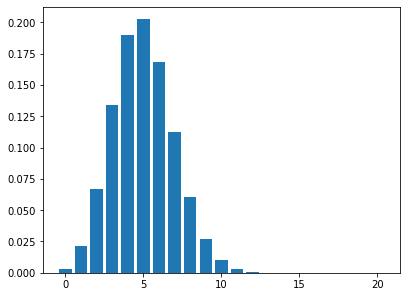

In [ ]:
X = Binomial('X', 20, Rational(1, 4))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 20, Rational(1, 4))
werte = list(range(21))
plt.bar(werte, [N(P(Eq(X, i))) for i in werte])
plt.show()
```

</details>

#### Aufgabe 6.6

Ein Multiple-Choice-Test hat 10 Fragen mit je 4 Antworten, von denen eine richtig ist. Jemand rät. Mit welcher Wahrscheinlichkeit hat er
mindestens 5 richtig (4 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 0.07813$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 10, Rational(1, 4))
N(P(X >= 5), 4)
```

</details>

#### Aufgabe 6.7

Ein Medikament wirkt bei 80 % der Patienten. Es werden 15 Patienten behandelt. Wie groß ist die Wahrscheinlichkeit, dass es bei höchstens 10 wirkt (4 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 0.1642$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 15, Rational(4, 5))
N(P(X <= 10), 4)
```

</details>

#### Aufgabe 6.8

**Fehlendes n:** Wie oft muss man einen Würfel mindestens werfen, damit mit mindestens 99 % Wahrscheinlichkeit wenigstens eine Sechs fällt?
Probiere n = 1, 2, 3, ... mit einer Schleife, bis `1 - Rational(5, 6)**n >= Rational(99, 100)` gilt, und gib n aus.

**Erwartete Ausgabe:**

$\displaystyle 26$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n = 1
while 1 - Rational(5, 6)**n < Rational(99, 100):
    n += 1
n
```

</details>

#### Aufgabe 6.9

**Fehlendes k:** X ist binomialverteilt mit n = 50 und p = 0,3. Bestimme das kleinste k mit P(X ≤ k) ≥ 0,95 mit einer Schleife.

**Erwartete Ausgabe:**

$\displaystyle 20$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 50, Rational(3, 10))
k = 0
while P(X <= k) < Rational(95, 100):
    k += 1
k
```

</details>

#### Aufgabe 6.10

**Fehlendes p:** Bei 10 Würfen soll die Wahrscheinlichkeit für „keinmal Treffer“ genau 0,1 sein. Löse `(1 − p)¹⁰ = 0,1` für p zwischen 0 und 1 (4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 0.2057$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solveset(Eq((1 - p)**10, Rational(1, 10)), p, domain=Interval(0, 1))
N(list(l)[0], 4)
```

</details>

#### Aufgabe 6.11

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
X = Binomial('X', 4, Rational(1, 2))
display(P(Eq(X, 0)))
display(E(X))
density(X).dict
```

In [ ]:
X = Binomial('X', 4, Rational(1, 2))
display(P(Eq(X, 0)))
display(E(X))
density(X).dict

## 7. Gemischte Übungen

#### Aufgabe 7.1

Beim „Mensch ärgere dich nicht“ darf man dreimal würfeln, um eine Sechs zu bekommen. Wie groß ist die Wahrscheinlichkeit, es zu schaffen?

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{91}{216}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
1 - Rational(5, 6)**3
```

</details>

#### Aufgabe 7.2

**Geburtstagsproblem:** Wie groß ist die Wahrscheinlichkeit, dass in einer Klasse mit 25 Personen mindestens zwei am selben Tag Geburtstag haben
(365 Tage, alle gleich wahrscheinlich)? Berechne `1 − (365·364·…·341)/365²⁵` mit `ff()` und gib das Ergebnis mit 4 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle 0.5687$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
N(1 - ff(365, 25) / Integer(365)**25, 4)
```

</details>

#### Aufgabe 7.3

Ein Schütze trifft mit 70 % Wahrscheinlichkeit. Er schießt 8-mal. Gib die Wahrscheinlichkeiten für 0 bis 8 Treffer mit 3 Ziffern als Liste aus
und den wahrscheinlichsten Wert (das k mit der größten Wahrscheinlichkeit).

**Erwartete Ausgabe:**

$\displaystyle \left[ 6.56 \cdot 10^{-5}, \  0.00122, \  0.01, \  0.0467, \  0.136, \  0.254, \  0.296, \  0.198, \  0.0576\right]$

$\displaystyle 6$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 8, Rational(7, 10))
wk = [N(P(Eq(X, i)), 3) for i in range(9)]
display(wk)
wk.index(max(wk))
```

</details>

#### Aufgabe 7.4

Ein Spiel: Man zahlt 1 € und wirft zwei Münzen. Bei zweimal Kopf bekommt man 3 €, bei genau einmal Kopf 1 €, sonst nichts.
Gib den erwarteten Gewinn aus.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{4}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
G = FiniteRV('G', {2: Rational(1, 4), 0: Rational(1, 2), -1: Rational(1, 4)})
E(G)
```

</details>

#### Aufgabe 7.5

Eine Firma weiß, dass 5 % ihrer Bauteile defekt sind. Sie prüft 100 Bauteile. Gib Erwartungswert und Standardabweichung der Anzahl defekter Teile
(mit 4 Ziffern) aus und die Wahrscheinlichkeit, dass mehr als 10 defekt sind (4 Ziffern).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 5$

$\displaystyle 2.179$

$\displaystyle 0.01147$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Binomial('X', 100, Rational(5, 100))
display(E(X), N(std(X), 4))
N(P(X > 10), 4)
```

</details>